# M1 · Data Profiling and Issue Log (pandas)

**Goal:** measure every data-quality problem in the five raw Customer 360 tables **before** anything is cleaned.
Nothing is changed in this notebook. Every problem found is written to an issue log, which later milestones (M2 to M7) use as their to-do list and audit trail.

**Outputs** (saved to `output/` in this folder; the client-facing report is built in M7):
- `issue_log.xlsx`: overview, issue log, checks that passed (0 rows affected) and column profile
- `m1_blank_cells.png`, `m1_issues_by_table.png`

All records are profiled. The clickstream file (500,000 rows) is read in chunks of 100,000 rows, which still covers the full file.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

RAW_DIR = Path("../../01_data_and_task/raw_data")
OUT_DIR = Path("output")  # detailed working outputs of this milestone; M7 builds the client report
OUT_DIR.mkdir(exist_ok=True)

FILES = {
    "customers":   "crm_50000_customers_dirty_v3.csv",
    "products":    "product_catalog_dirty_30pct.csv",
    "orders":      "orders_300k_dirty.csv",
    "tickets":     "support_tickets_30000_dirty.csv",
    "clickstream": "clickstream_500k_events.csv",
}

# Every column is read as text and empty cells stay "" so no dirty value is silently converted.
READ_OPTS = dict(dtype=str, keep_default_na=False, encoding="utf-8")
CHUNK_SIZE = 100_000

# The raw files were exported on 2025-12-02 (file timestamp); any event after this date cannot be real.
SNAPSHOT_DATE = pd.Timestamp("2025-12-02")
AFTER_SNAPSHOT = SNAPSHOT_DATE + pd.Timedelta(days=1)  # first moment after the export day

## 2. Load raw data

In [2]:
tables = {
    name: pd.read_csv(RAW_DIR / file, **READ_OPTS)
    for name, file in FILES.items()
    if name != "clickstream"
}

for name, df in tables.items():
    print(f"{name:<12} {df.shape[0]:>7,} rows x {df.shape[1]} columns")

customers     50,000 rows x 14 columns
products         500 rows x 4 columns
orders       300,000 rows x 8 columns
tickets       30,000 rows x 8 columns


In [3]:
def read_clickstream():
    """Yield the full clickstream file in chunks of CHUNK_SIZE rows."""
    return pd.read_csv(RAW_DIR / FILES["clickstream"], chunksize=CHUNK_SIZE, **READ_OPTS)


click_rows = sum(len(chunk) for chunk in read_clickstream())
click_cols = pd.read_csv(RAW_DIR / FILES["clickstream"], nrows=0).columns.tolist()
print(f"clickstream  {click_rows:>7,} rows x {len(click_cols)} columns (read in chunks)")

ROWS = {name: len(df) for name, df in tables.items()} | {"clickstream": click_rows}

clickstream  500,000 rows x 8 columns (read in chunks)


## 3. Helpers

Every finding goes through `log_issue`, so the issue log always has the same columns: where the problem is, how many rows it affects, real examples, the planned action and the milestone that will fix it.

In [4]:
issues = []
passed = []


def examples(values, k=3):
    """Up to k distinct example values, quoted so leading/trailing spaces stay visible."""
    uniq = pd.Series(values).drop_duplicates().head(k)
    return "; ".join(repr(v) for v in uniq)


def log_issue(table, column, issue, count, sample, action, milestone):
    count = int(count)
    if count == 0:
        passed.append({"table": table, "column": column, "check": issue, "rows_affected": 0})
        return
    issues.append({
        "table": table,
        "column": column,
        "issue": issue,
        "rows_affected": count,
        "pct_of_rows": round(count / ROWS[table] * 100, 2),
        "examples": sample,
        "planned_action": action,
        "milestone": milestone,
    })


def check(table, column, mask, issue, action, milestone, values=None):
    """Log an issue from a boolean mask over a column of an in-memory table."""
    values = tables[table][column] if values is None else values
    log_issue(table, column, issue, mask.sum(), examples(values[mask]), action, milestone)


PLACEHOLDERS = {"nan", "null", "none", "n/a", "na", "unknown", "-", "?"}


def is_blank(s):
    return s.str.strip().eq("")


def has_outer_space(s):
    return s.ne(s.str.strip()) & ~is_blank(s)


def is_placeholder(s):
    return s.str.strip().str.lower().isin(PLACEHOLDERS)


def same_value(values, mask):
    """Note added when every affected row holds one identical value (an injected placeholder)."""
    uniq = values[mask].unique()
    return f" (all rows hold the same value {uniq[0]!r})" if mask.sum() > 1 and len(uniq) == 1 else ""


def obj(s):
    """pandas 3 strings use the RE2 engine, which has no backreferences; object dtype uses Python's re."""
    return s.astype(object)

## 4. Table overview

In [5]:
overview = pd.DataFrame(
    [
        {
            "table": name,
            "file": FILES[name],
            "file_size_mb": round((RAW_DIR / FILES[name]).stat().st_size / 1024**2, 2),
            "rows": ROWS[name],
            "columns": len(tables[name].columns) if name in tables else len(click_cols),
            "column_names": ", ".join(tables[name].columns if name in tables else click_cols),
        }
        for name in FILES
    ]
)
overview

,table,file,file_size_mb,rows,columns,column_names
0,customers,crm_50000_customers_dirty_v3.csv,10.62,50000,14,"customer_id, first_name, last_name, email, phone_number, gender, dob, signup..."
1,products,product_catalog_dirty_30pct.csv,0.02,500,4,"product_id, product_name, category, price"
2,orders,orders_300k_dirty.csv,34.06,300000,8,"order_id, customer_id, product_id, order_amount, order_date, payment_method,..."
3,tickets,support_tickets_30000_dirty.csv,4.17,30000,8,"ticket_id, customer_id, issue_type, ticket_created, ticket_resolved, resolut..."
4,clickstream,clickstream_500k_events.csv,121.83,500000,8,"event_id, session_id, customer_id, event_type, page_url, device_id, timestam..."


## 5. Generic checks (all tables)

Applied to every column of every table:
- **Blank**: empty or whitespace only
- **Leading/trailing spaces**
- **Placeholder text** such as `NaN`, `null`, `N/A`, `unknown`
- **Exact duplicate rows**: identical to an earlier row in every column

For clickstream, the counts are added up chunk by chunk. Duplicate rows are found by hashing every row and comparing the hashes of the whole file, so duplicates in different chunks are still caught.

In [6]:
GENERIC_ACTION = {
    "blank value": "Convert to proper null; fill only if a reliable source exists, otherwise keep null",
    "leading/trailing spaces": "Trim",
    "placeholder text instead of a value": "Convert to null",
}
MILESTONE = {"customers": "M2", "products": "M3", "orders": "M4", "clickstream": "M5", "tickets": "M6"}

generic_rows = []
for name, df in tables.items():
    for col in df.columns:
        s = df[col]
        for issue, mask in [
            ("blank value", is_blank(s)),
            ("leading/trailing spaces", has_outer_space(s)),
            ("placeholder text instead of a value", is_placeholder(s)),
        ]:
            check(name, col, mask, issue, GENERIC_ACTION[issue], MILESTONE[name])
    dup = df.duplicated()
    log_issue(name, "(all)", "exact duplicate row", dup.sum(), "",
              "Drop, keep first occurrence", MILESTONE[name])

# clickstream, chunk by chunk
click_counts = {}
click_examples = {}
row_hashes = []
for chunk in read_clickstream():
    row_hashes.append(pd.util.hash_pandas_object(chunk, index=False))
    for col in chunk.columns:
        s = chunk[col]
        for issue, mask in [
            ("blank value", is_blank(s)),
            ("leading/trailing spaces", has_outer_space(s)),
            ("placeholder text instead of a value", is_placeholder(s)),
        ]:
            key = (col, issue)
            click_counts[key] = click_counts.get(key, 0) + int(mask.sum())
            if key not in click_examples and mask.any():
                click_examples[key] = examples(s[mask])

for (col, issue), n in click_counts.items():
    log_issue("clickstream", col, issue, n, click_examples.get((col, issue), ""), GENERIC_ACTION[issue], "M5")

row_hashes = pd.concat(row_hashes, ignore_index=True)
log_issue("clickstream", "(all)", "exact duplicate row", row_hashes.duplicated().sum(), "",
          "Drop, keep first occurrence", "M5")

pd.DataFrame(issues)

,table,column,issue,rows_affected,pct_of_rows,examples,planned_action,milestone
0,customers,first_name,leading/trailing spaces,3124,6.25,' Caitlin'; 'Jose '; 'Dana ',Trim,M2
1,customers,last_name,leading/trailing spaces,3134,6.27,' Cantu'; ' Weeks'; ' Hernandez',Trim,M2
2,customers,email,blank value,1040,2.08,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M2
3,customers,(all),exact duplicate row,1021,2.04,,"Drop, keep first occurrence",M2
4,products,product_name,leading/trailing spaces,37,7.40,' Bit Its'; 'Section Drive '; ' Nature While',Trim,M3
5,products,category,blank value,30,6.00,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M3
6,products,category,leading/trailing spaces,12,2.40,'electronics '; 'sports '; 'kitchen ',Trim,M3
7,products,price,leading/trailing spaces,35,7.00,' 32309.95'; ' 35426.08'; '46482.66 ',Trim,M3
8,products,price,placeholder text instead of a value,26,5.20,'NaN',Convert to null,M3
9,orders,order_amount,leading/trailing spaces,25592,8.53,'27100.3 '; ' 40344.97'; '41711.08 ',Trim,M4


### Blank cells per column

A column-level view of how much is missing, used for the chart in section 12.

In [7]:
blank_rows = []
for name, df in tables.items():
    for col in df.columns:
        blank_rows.append({"table": name, "column": col, "blank_pct": is_blank(df[col]).mean() * 100})
for col in click_cols:
    blank_rows.append({"table": "clickstream", "column": col,
                       "blank_pct": click_counts[(col, "blank value")] / click_rows * 100})

blank_pct = pd.DataFrame(blank_rows)
blank_pct[blank_pct["blank_pct"] > 0].sort_values("blank_pct", ascending=False).round(2)

,table,column,blank_pct
36,clickstream,customer_id,30.11
30,tickets,ticket_resolved,6.08
16,products,category,6.00
22,orders,order_date,5.97
29,tickets,ticket_created,5.96
25,orders,quantity,5.02
40,clickstream,timestamp,4.03
3,customers,email,2.08
38,clickstream,page_url,1.66


## 6. Customers

The CRM table should hold one row per customer. Checks:
- **IDs**: repeated `customer_id` rows that are not exact copies (conflicting versions of one profile)
- **Names**: letter case, noise characters (digits, `*`, `!`, `@`), doubled first letter (`KKeevvin`)
- **Email**: invalid format, generic `shared####@` addresses, one email used by several customer IDs
- **Phone**: many formats, extensions, NANP area codes starting with 0 or 1 (cannot be a real US number)
- **Dates**: format, plausible range, signup before birth or before age 13
- **Address / location**: all-caps addresses, US state combined with a non-US country
- **Devices**: several device IDs packed into one cell

In [8]:
c = tables["customers"]

# IDs
exact_dup = c.duplicated()
id_repeat = c["customer_id"].duplicated() & ~exact_dup
check("customers", "customer_id", id_repeat,
      "same customer_id repeated with different values (conflicting versions)",
      "Merge into one golden record per customer_id", "M2")

# Names
for col in ["first_name", "last_name"]:
    s = c[col].str.strip()
    noise = s.str.contains(r"[^A-Za-z '\-]", regex=True)
    letters = s.str.replace(r"[^A-Za-z '\-]", "", regex=True)
    bad_case = letters.ne(letters.str.title()) & letters.ne("")
    doubled = obj(s).str.match(r"^([A-Za-z])\1").astype(bool)
    check("customers", col, noise, "noise characters (digits or symbols) in name",
          "Remove digits and symbols", "M2", c[col])
    check("customers", col, bad_case, "inconsistent letter case",
          "Convert to title case", "M2", c[col])
    check("customers", col, doubled, "possible doubled-letter typo (e.g. 'KKeevvin')",
          "Rebuild from email local part when it confirms the name, otherwise flag", "M2", c[col])

# Email
email = c["email"].str.strip()
valid_email = email.str.match(r"^[a-z0-9._%+-]+@[a-z0-9.-]+\.[a-z]{2,}$")
check("customers", "email", ~valid_email & ~is_blank(email), "invalid email format", "Flag", "M2")
shared = email.str.match(r"^shared\d+@")
check("customers", "email", shared, "generic shared address (shared####@...), not a personal email",
      "Keep but mark as non-unique; never use as a merge key", "M2")
ids_per_email = c[~is_blank(email)].groupby(email)["customer_id"].transform("nunique")
multi_email = pd.Series(False, index=c.index)
multi_email.loc[ids_per_email.index] = ids_per_email.gt(1)
check("customers", "email", multi_email & ~shared, "same personal email used by different customer_id",
      "Review as possible duplicate customers; flag, do not merge automatically", "M2")

# Phone
phone = c["phone_number"].str.strip()
phone_shape = phone.str.replace(r"\d", "9", regex=True)
main = phone.str.split("x").str[0]
digits = main.str.replace(r"\D", "", regex=True)
digits = digits.where(~(digits.str.len().eq(13) & digits.str.startswith("001")), digits.str[3:])
digits = digits.where(~(digits.str.len().eq(11) & digits.str.startswith("1")), digits.str[1:])
log_issue("customers", "phone_number", f"phone numbers in {phone_shape.nunique()} different formats, none in E.164",
          len(phone), examples(phone.groupby(phone_shape).first().head(4)),
          "Standardise to E.164 (+1XXXXXXXXXX)", "M2")
check("customers", "phone_number", phone.str.contains("x"), "phone extension mixed into the number",
      "Move extension to its own column", "M2")
check("customers", "phone_number", digits.str.len().ne(10), "phone does not have 10 digits",
      "Flag, keep raw value", "M2")
bad_area = digits.str.len().eq(10) & digits.str[0].isin(["0", "1"])
check("customers", "phone_number", bad_area, "invalid US area code (starts with 0 or 1)",
      "Flag; do not convert to E.164", "M2")

# Dates
dob = pd.to_datetime(c["dob"], format="%Y-%m-%d", errors="coerce")
signup = pd.to_datetime(c["signup_date"], format="%Y-%m-%d", errors="coerce")
check("customers", "dob", dob.isna(), "unparseable date", "Flag", "M2")
check("customers", "signup_date", signup.isna(), "unparseable date", "Flag", "M2")
age_at_signup = (signup - dob).dt.days / 365.25
check("customers", "signup_date", signup >= AFTER_SNAPSHOT, "signup after the data export date", "Flag", "M2")
check("customers", "signup_date", age_at_signup < 0, "signup before date of birth", "Flag", "M2")
check("customers", "signup_date", (age_at_signup >= 0) & (age_at_signup < 13),
      "customer younger than 13 at signup", "Flag", "M2")
print("dob range:", dob.min().date(), "to", dob.max().date())
print("signup range:", signup.min().date(), "to", signup.max().date())

# Address / location
addr = c["address"]
check("customers", "address", addr.str.isupper(), "address written in all caps", "Convert to title case", "M2")
non_us = ~c["country"].str.strip().str.lower().isin(["united states", "united states of america"])
check("customers", "country", non_us,
      "US state combined with a non-US country (state and country contradict)",
      "Flag; source cannot tell which field is correct", "M2")

# Devices
multi_dev = c["device_id(s)"].str.contains(";")
check("customers", "device_id(s)", multi_dev, "several device IDs packed in one cell",
      "Split into a separate customer-device table", "M2")

pd.DataFrame([i for i in issues if i["table"] == "customers"])

dob range: 1954-12-20 to 2007-12-07
signup range: 2013-12-02 to 2025-12-01


,table,column,issue,rows_affected,pct_of_rows,examples,planned_action,milestone
0,customers,first_name,leading/trailing spaces,3124,6.25,' Caitlin'; 'Jose '; 'Dana ',Trim,M2
1,customers,last_name,leading/trailing spaces,3134,6.27,' Cantu'; ' Weeks'; ' Hernandez',Trim,M2
2,customers,email,blank value,1040,2.08,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M2
3,customers,(all),exact duplicate row,1021,2.04,,"Drop, keep first occurrence",M2
4,customers,customer_id,same customer_id repeated with different values (conflicting versions),779,1.56,'ce815388-3335-4190-9eb6-987ba2f82ad2'; '59ab3792-667a-4a24-9482-439bbdb1409...,Merge into one golden record per customer_id,M2
5,customers,first_name,noise characters (digits or symbols) in name,3104,6.21,'Tho8mas'; 'Tara*'; 'Jonathan!',Remove digits and symbols,M2
6,customers,first_name,inconsistent letter case,6272,12.54,'mARIA'; 'KKeevvin'; 'JAY',Convert to title case,M2
7,customers,first_name,possible doubled-letter typo (e.g. 'KKeevvin'),1582,3.16,'KKeevvin'; 'JJeennnifer'; 'DDaavvid',"Rebuild from email local part when it confirms the name, otherwise flag",M2
8,customers,last_name,noise characters (digits or symbols) in name,3086,6.17,'Ha0rt'; 'Thompson*'; 'Schneide9r',Remove digits and symbols,M2
9,customers,last_name,inconsistent letter case,6280,12.56,'day'; 'JJoonnes'; 'sMITH',Convert to title case,M2


## 7. Products

The catalog should have one clean name, one of a fixed set of categories and a positive numeric price per product.

In [9]:
p = tables["products"]
CATEGORIES = {"automotive", "beauty", "clothing", "electronics", "home", "kitchen", "sports", "toys"}

name = p["product_name"].str.strip()
check("products", "product_name", name.str.contains(r"[a-z][A-Z]", regex=True),
      "missing space between words (e.g. 'UsuallyHear')", "Insert space before inner capital", "M3")
check("products", "product_name", name.str.contains(r"[^A-Za-z ]", regex=True),
      "noise characters (digits or symbols) in name", "Remove digits and symbols", "M3", p["product_name"])
check("products", "product_name", name.str.lower().str.contains("aa"),
      "doubled-letter typo 'aa' (e.g. 'Beaautiful')", "Replace 'aa' with 'a'", "M3", p["product_name"])
check("products", "product_name", name.str.isupper(), "name written in all caps", "Convert to title case", "M3")
check("products", "product_name", name.str.islower(), "name written in lower case", "Convert to title case", "M3")

cat = p["category"]
bad_cat = ~cat.isin(CATEGORIES) & ~is_blank(cat)
check("products", "category", bad_cat,
      f"non-standard category value ({cat[bad_cat].nunique()} variants: case, leetspeak, truncation, suffixes)",
      "Map every variant to one of 8 standard categories", "M3")

price = p["price"].str.strip()
price_num = pd.to_numeric(price, errors="coerce")
for issue, mask, action in [
    ("non-numeric price (thousand separator)", price_num.isna() & ~is_placeholder(price),
     "Unreliable placeholder: convert to null and flag"),
    ("negative price", price_num < 0, "Convert to null and flag"),
    ("zero price", price_num == 0, "Convert to null and flag"),
]:
    check("products", "price", mask, issue + same_value(price, mask), action, "M3")
print(f"{CATEGORIES=}")
print("valid price range:", price_num[price_num > 0].min(), "to", price_num[price_num > 0].max())

pd.DataFrame([i for i in issues if i["table"] == "products"])

CATEGORIES={'electronics', 'beauty', 'sports', 'toys', 'kitchen', 'home', 'automotive', 'clothing'}
valid price range: 107.85 to 851374.78


,table,column,issue,rows_affected,pct_of_rows,examples,planned_action,milestone
0,products,product_name,leading/trailing spaces,37,7.4,' Bit Its'; 'Section Drive '; ' Nature While',Trim,M3
1,products,category,blank value,30,6.0,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M3
2,products,category,leading/trailing spaces,12,2.4,'electronics '; 'sports '; 'kitchen ',Trim,M3
3,products,price,leading/trailing spaces,35,7.0,' 32309.95'; ' 35426.08'; '46482.66 ',Trim,M3
4,products,price,placeholder text instead of a value,26,5.2,'NaN',Convert to null,M3
5,products,product_name,missing space between words (e.g. 'UsuallyHear'),23,4.6,'StartWear'; 'StockYard'; 'BringOffice',Insert space before inner capital,M3
6,products,product_name,noise characters (digits or symbols) in name,30,6.0,'Magazine Health6'; 'Century Old!'; 'My Employee7',Remove digits and symbols,M3
7,products,product_name,doubled-letter typo 'aa' (e.g. 'Beaautiful'),11,2.2,'Open Beaautiful'; 'By Speaak'; 'Thaat Gun',Replace 'aa' with 'a',M3
8,products,product_name,name written in all caps,18,3.6,'MEAN YOUR'; 'BABY SOMETIMES'; 'AIR SON',Convert to title case,M3
9,products,product_name,name written in lower case,17,3.4,'current agreement'; 'ago mouth'; 'ever audience',Convert to title case,M3


## 8. Orders

Every order should point to a known customer and product, with a positive amount, a valid date, a positive whole quantity, and one of a fixed set of payment methods and statuses.
Outliers in `order_amount` are measured with the IQR rule on valid amounts (NumPy), so M4 knows how many to review.

In [10]:
o = tables["orders"]
PAYMENT_METHODS = {"card", "cash", "upi", "wallet"}
STATUSES = {"success", "failed", "refunded"}

# Amount
amount = o["order_amount"].str.strip()
amount_num = pd.to_numeric(amount, errors="coerce")
for issue, mask, action in [
    ("non-numeric amount (thousand separator)", amount_num.isna() & ~is_placeholder(amount),
     "Unreliable placeholder: convert to null and flag"),
    ("negative amount", amount_num < 0, "Convert to null and flag"),
    ("zero amount", amount_num == 0, "Convert to null and flag"),
]:
    check("orders", "order_amount", mask, issue + same_value(amount, mask), action, "M4")

valid = amount_num[amount_num > 0].to_numpy()
q1, q3 = np.percentile(valid, [25, 75])
upper = q3 + 1.5 * (q3 - q1)
outlier = amount_num > upper
check("orders", "order_amount", outlier, f"high outlier (IQR rule, above {upper:,.2f})",
      "Keep, flag for review (may be genuine bulk orders)", "M4")
print(f"Q1={q1:,.2f}  Q3={q3:,.2f}  upper fence={upper:,.2f}  max={valid.max():,.2f}")

# Date
od = o["order_date"].str.strip()
iso = pd.to_datetime(od, format="%Y-%m-%d", errors="coerce")
check("orders", "order_date", od.eq("2024/31/01"), "impossible date '2024/31/01' (month 31)",
      "Convert to null and flag", "M4")
ddmm = od.str.match(r"^\d{2}-\d{2}-\d{4}$")
check("orders", "order_date", ddmm, "date in DD-MM-YYYY format" + same_value(od, ddmm),
      "Parse as day-month-year", "M4")
ymd_hm = od.str.match(r"^\d{4}/\d{2}/\d{2} \d{2}:\d{2}$")
check("orders", "order_date", ymd_hm,
      "date with time in YYYY/MM/DD HH:MM format, day/month order ambiguous" + same_value(od, ymd_hm),
      "Parse as year/month/day (ISO order), drop time, flag as ambiguous", "M4")
iso_ts = pd.to_datetime(od.where(od.str.contains("T")), format="ISO8601", errors="coerce")
check("orders", "order_date", iso_ts.notna(), "full timestamp instead of a date (YYYY-MM-DDTHH:MM:SS.ffffff)",
      "Keep date part only", "M4")
check("orders", "order_date", iso.combine_first(iso_ts) >= AFTER_SNAPSHOT,
      "order date after the data export date (future)", "Convert to null and flag", "M4")
other = iso.isna() & iso_ts.isna() & ~is_blank(od) & ~od.eq("2024/31/01") & ~ddmm & ~ymd_hm
check("orders", "order_date", other, "other unparseable date", "Flag", "M4")
print("ISO date range:", iso.min().date(), "to", iso.max().date())

# Categoricals
for col, allowed in [("payment_method", PAYMENT_METHODS), ("status", STATUSES)]:
    s = o[col]
    bad = ~s.isin(allowed)
    check("orders", col, bad,
          f"non-standard value ({s[bad].nunique()} variants: case, typos, abbreviations, spaces)",
          f"Map to {sorted(allowed)}", "M4")

# Quantity
qty = o["quantity"].str.strip()
qty_num = pd.to_numeric(qty, errors="coerce")
check("orders", "quantity", qty_num.isna() & ~is_blank(qty), "quantity written as a word (e.g. 'five')",
      "Convert word to number", "M4")
check("orders", "quantity", qty.str.contains(r"\.", regex=True), "quantity with decimal (e.g. '2.0')",
      "Convert to whole number when the decimal part is .0", "M4")
check("orders", "quantity", qty_num < 0, "negative quantity", "Convert to null and flag", "M4")
check("orders", "quantity", qty_num == 0, "zero quantity", "Convert to null and flag", "M4")

# Relationships
cust_ids = set(c["customer_id"])
prod_ids = set(p["product_id"])
check("orders", "customer_id", ~o["customer_id"].isin(cust_ids), "orphan: customer_id not in customers",
      "Keep, flag as orphan", "M4")
check("orders", "product_id", ~o["product_id"].isin(prod_ids), "orphan: product_id not in products",
      "Keep, flag as orphan", "M4")

pd.DataFrame([i for i in issues if i["table"] == "orders"])

Q1=13,273.43  Q3=39,593.70  upper fence=79,074.10  max=999,969.87


ISO date range: 2023-12-03 to 2025-12-01


,table,column,issue,rows_affected,pct_of_rows,examples,planned_action,milestone
0,orders,order_amount,leading/trailing spaces,25592,8.53,'27100.3 '; ' 40344.97'; '41711.08 ',Trim,M4
1,orders,order_amount,placeholder text instead of a value,12830,4.28,'NaN',Convert to null,M4
2,orders,order_date,blank value,17914,5.97,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M4
3,orders,payment_method,leading/trailing spaces,21553,7.18,'UPI '; ' upi',Trim,M4
4,orders,status,leading/trailing spaces,25658,8.55,' FAILED'; 'refunded ',Trim,M4
5,orders,quantity,blank value,15050,5.02,' ',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M4
6,orders,order_amount,"non-numeric amount (thousand separator) (all rows hold the same value '1,200')",12897,4.30,"'1,200'",Unreliable placeholder: convert to null and flag,M4
7,orders,order_amount,negative amount (all rows hold the same value '-50'),12810,4.27,'-50',Convert to null and flag,M4
8,orders,order_amount,zero amount (all rows hold the same value '0'),12988,4.33,'0',Convert to null and flag,M4
9,orders,order_amount,"high outlier (IQR rule, above 79,074.10)",12883,4.29,'696397.36'; '816458.15'; '775197.14',"Keep, flag for review (may be genuine bulk orders)",M4


## 9. Support tickets

Each ticket should have one of four issue types, a valid created and resolved timestamp (resolved after created), a resolution time that matches those timestamps, one of three sentiments and a clean agent name.

In [11]:
t = tables["tickets"]
ISSUE_TYPES = {"delay", "payment", "product", "refund"}
SENTIMENTS = {"negative", "neutral", "positive"}

for col, allowed in [("issue_type", ISSUE_TYPES), ("sentiment", SENTIMENTS)]:
    s = t[col]
    bad = ~s.isin(allowed)
    check("tickets", col, bad,
          f"non-standard value ({s[bad].nunique()} variants: case, leetspeak, reversed, truncated, suffixes)",
          f"Map to {sorted(allowed)}", "M6")

parsed = {}
for col in ["ticket_created", "ticket_resolved"]:
    s = t[col].str.strip()
    parsed[col] = pd.to_datetime(s, format="ISO8601", errors="coerce")
    impossible = parsed[col].isna() & ~is_blank(s)
    check("tickets", col, impossible,
          f"impossible or unparseable timestamp ({s[impossible].nunique()} patterns: month 15/31, hour 28)",
          "Convert to null and flag", "M6")

created, resolved = parsed["ticket_created"], parsed["ticket_resolved"]
for col in ["ticket_created", "ticket_resolved"]:
    check("tickets", col, parsed[col] >= AFTER_SNAPSHOT, "timestamp after the data export date (future)",
          "Convert to null and flag", "M6")
check("tickets", "ticket_resolved", resolved < created, "resolved before created",
      "Flag; keep both values", "M6")

hours = pd.to_numeric(t["resolution_time_hours"], errors="coerce")
actual = (resolved - created).dt.total_seconds() / 3600
both = created.notna() & resolved.notna() & hours.notna()
mismatch = both & (hours - actual).abs().gt(1)
check("tickets", "resolution_time_hours", mismatch,
      "resolution_time_hours does not match resolved minus created (more than 1 hour off)",
      "Recalculate from timestamps when both are valid", "M6")
check("tickets", "resolution_time_hours", hours.isna(), "non-numeric hours", "Flag", "M6")

agent = t["support_agent"].str.strip()
check("tickets", "support_agent", agent.str.contains(r"[^A-Za-z .'\-]|--|\.\.", regex=True) | agent.str.endswith("-"),
      "noise characters in agent name (e.g. trailing '--')", "Remove noise characters", "M6", t["support_agent"])
check("tickets", "support_agent", obj(agent).str.contains(r"aa|ii|uu|([a-z])\1\1|\b([A-Z])\2(?=[a-z])", regex=True).astype(bool),
      "possible doubled-letter typo in agent name (e.g. 'Kaathy')", "Fix only where a clean spelling of the same agent exists, otherwise flag",
      "M6", t["support_agent"])

check("tickets", "customer_id", ~t["customer_id"].isin(cust_ids), "orphan: customer_id not in customers",
      "Keep, flag as orphan", "M6")

pd.DataFrame([i for i in issues if i["table"] == "tickets"])

C:\Users\msibr\AppData\Local\Temp\ipykernel_17668\3016371695.py:40: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  check("tickets", "support_agent", obj(agent).str.contains(r"aa|ii|uu|([a-z])\1\1|\b([A-Z])\2(?=[a-z])", regex=True).astype(bool),


,table,column,issue,rows_affected,pct_of_rows,examples,planned_action,milestone
0,tickets,issue_type,leading/trailing spaces,2245,7.48,' refund'; 'delay '; ' product',Trim,M6
1,tickets,ticket_created,blank value,1789,5.96,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M6
2,tickets,ticket_resolved,blank value,1823,6.08,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M6
3,tickets,sentiment,leading/trailing spaces,2206,7.35,'negative '; ' neutral'; ' negative',Trim,M6
4,tickets,support_agent,leading/trailing spaces,2574,8.58,' Felicia Rodgers'; 'Charles Williams '; ' Teresa Davis',Trim,M6
5,tickets,issue_type,"non-standard value (31 variants: case, leetspeak, reversed, truncated, suffi...",8739,29.13,'pro'; 'r3fund'; 'refundx',"Map to ['delay', 'payment', 'product', 'refund']",M6
6,tickets,sentiment,"non-standard value (15 variants: case, leetspeak, reversed, truncated, suffi...",9000,30.00,'NEGATIVE'; 'POSITIVE'; 'negative ',"Map to ['negative', 'neutral', 'positive']",M6
7,tickets,ticket_created,"impossible or unparseable timestamp (3 patterns: month 15/31, hour 28)",5390,17.97,'2025-12-12T28:77:10'; '2024/31/01'; '31-15-2023',Convert to null and flag,M6
8,tickets,ticket_resolved,"impossible or unparseable timestamp (3 patterns: month 15/31, hour 28)",5324,17.75,'2025-12-12T28:77:10'; '31-15-2023'; '2024/31/01',Convert to null and flag,M6
9,tickets,ticket_created,timestamp after the data export date (future),1821,6.07,'2026-06-22T15:41:44.348698'; '2027-01-01T15:41:44.414499'; '2026-11-13T15:4...,Convert to null and flag,M6


## 10. Clickstream

Profiled chunk by chunk over the full 500,000 rows. Checks:
- duplicate `event_id`
- events with no customer (anonymous visitors, normal for web traffic) and events whose customer is unknown
- URL variants: upper case, missing scheme, extra slashes, wrong `/prod/` path
- timestamp formats and impossible timestamps
- products in URLs that are not in the catalog

In [12]:
prod_ids = set(p["product_id"])
counts = {}
samples = {}
event_ids = []
event_types = pd.Series(dtype="int64")
ts_formats = pd.Series(dtype="int64")


def add(key, mask, values):
    counts[key] = counts.get(key, 0) + int(mask.sum())
    if key not in samples and mask.any():
        samples[key] = examples(values[mask])


for chunk in read_clickstream():
    event_ids.append(chunk["event_id"])
    event_types = event_types.add(chunk["event_type"].value_counts(), fill_value=0)

    cust = chunk["customer_id"]
    add(("customer_id", "unknown customer_id (not in customers)"), ~is_blank(cust) & ~cust.isin(cust_ids), cust)

    dev = chunk["device_id"].str.strip()
    add(("device_id", "device_id UUID in upper or mixed case"),
        dev.str.fullmatch(r"(?i)[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}") & ~dev.str.fullmatch(r"[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}"), dev)
    add(("device_id", "device_id without dashes (32 hex characters)"), dev.str.fullmatch(r"[0-9a-fA-F]{32}"), dev)
    add(("device_id", "placeholder device_id ('invalid-device-N')"), dev.str.fullmatch(r"invalid-device-\d+"), dev)

    url = chunk["page_url"].str.strip()
    add(("page_url", "URL in upper case"), url.str.replace(r"PROD-\d+", "", regex=True).str.contains(r"[A-Z]", regex=True), url)
    add(("page_url", "URL without https:// scheme"), ~is_blank(url) & ~url.str.lower().str.startswith(("http://", "https://")), url)
    add(("page_url", "URL with repeated slashes (e.g. 'http://///', '///')"),
        url.str.replace(r"^https?://", "", regex=True).str.contains("//"), url)
    add(("page_url", "non-standard product path '/prod/' instead of '/product/'"), url.str.lower().str.contains("/prod/"), url)
    prod_in_url = url.str.upper().str.extract(r"(PROD-\d+)")[0]
    add(("page_url", "product in URL not in catalog"), prod_in_url.notna() & ~prod_in_url.isin(prod_ids), url)

    ts = chunk["timestamp"].str.strip()
    fmt = ts.str.replace(r"\d", "9", regex=True)
    ts_formats = ts_formats.add(fmt[~is_blank(ts)].value_counts(), fill_value=0)
    standard = fmt.eq("9999-99-99T99:99:99.999999+99:99")
    add(("timestamp", "timestamp not in standard ISO 8601 with timezone"), ~standard & ~is_blank(ts), ts)
    ts_parsed = pd.to_datetime(ts.str.replace("/", "-"), format="ISO8601", errors="coerce", utc=True)
    add(("timestamp", "impossible or unparseable timestamp"), ts_parsed.isna() & ~is_blank(ts), ts)
    add(("timestamp", "timestamp after the data export date (future)"),
        ts_parsed >= AFTER_SNAPSHOT.tz_localize("UTC"), ts)

ACTIONS = {
    "unknown customer_id (not in customers)": ("Keep, flag as orphan", "M5"),
    "URL in upper case": ("Lower-case the URL", "M5"),
    "URL without https:// scheme": ("Add https://", "M5"),
    "URL with repeated slashes (e.g. 'http://///', '///')": ("Collapse repeated slashes, remove trailing slash", "M5"),
    "non-standard product path '/prod/' instead of '/product/'": ("Rewrite to /product/", "M5"),
    "product in URL not in catalog": ("Keep, flag as orphan", "M5"),
    "timestamp not in standard ISO 8601 with timezone": ("Parse every format, store as UTC", "M5"),
    "impossible or unparseable timestamp": ("Convert to null and flag", "M5"),
    "timestamp after the data export date (future)": ("Convert to null and flag", "M5"),
    "device_id UUID in upper or mixed case": ("Lower-case", "M5"),
    "device_id without dashes (32 hex characters)": ("Insert dashes at the standard 8-4-4-4-12 positions", "M5"),
    "placeholder device_id ('invalid-device-N')": ("Convert to null and flag", "M5"),
}
for (col, issue), n in counts.items():
    action, ms = ACTIONS[issue]
    log_issue("clickstream", col, issue, n, samples.get((col, issue), ""), action, ms)

event_ids = pd.concat(event_ids, ignore_index=True)
log_issue("clickstream", "event_id", "duplicate event_id", event_ids.duplicated().sum(),
          examples(event_ids[event_ids.duplicated()]), "Keep one event per event_id", "M5")

anon = click_counts[("customer_id", "blank value")]
print(f"anonymous events (no customer_id): {anon:,} ({anon / click_rows:.1%}); normal for web traffic, kept as null")
print("event types:", event_types.astype(int).to_dict())
print("timestamp formats:")
print(ts_formats.astype(int).sort_values(ascending=False).to_string())

pd.DataFrame([i for i in issues if i["table"] == "clickstream"])

anonymous events (no customer_id): 150,553 (30.1%); normal for web traffic, kept as null
event types: {'add_to_cart': 74827, 'login': 49813, 'page_view': 300414, 'search': 74946}
timestamp formats:
timestamp
9999-99-99T99:99:99.999999+99:99    419763
9999-99-99T99:99:99                  20102
9999/99/99 99:99:99                  20011
9999-99-99 99:99:99.999999+99:99     19962
9999-99-99T99:99:99+99:99                2


,table,column,issue,rows_affected,pct_of_rows,examples,planned_action,milestone
0,clickstream,customer_id,blank value,150553,30.11,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M5
1,clickstream,page_url,blank value,8305,1.66,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M5
2,clickstream,device_id,leading/trailing spaces,9915,1.98,'8ef2607c-31a4-43d9-86df-3553522de9b4 '; '60854a02-39b3-4457-b57f-b09d0dfc09...,Trim,M5
3,clickstream,timestamp,blank value,20160,4.03,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M5
4,clickstream,device_id,device_id UUID in upper or mixed case,5068,1.01,'BB463A08-45D5-4A86-829A-C7FECE8E2772'; '754C3CD8-373C-4886-AE84-135E2A5A92D...,Lower-case,M5
5,clickstream,device_id,device_id without dashes (32 hex characters),5030,1.01,'17213ae6f43f48e48b3dbf2719109f2d'; 'eb65ff4cd2954764b5ae419e25e8b258'; 'db4...,Insert dashes at the standard 8-4-4-4-12 positions,M5
6,clickstream,device_id,placeholder device_id ('invalid-device-N'),4986,1.00,'invalid-device-6314'; 'invalid-device-1555'; 'invalid-device-5129',Convert to null and flag,M5
7,clickstream,page_url,URL in upper case,8482,1.70,'HTTPS://SHOP.EXAMPLE.COM/PRODUCT/PROD-0412'; 'HTTPS://SHOP.EXAMPLE.COM/PROD...,Lower-case the URL,M5
8,clickstream,page_url,URL without https:// scheme,8195,1.64,'shop.example.com/product/PROD-0358'; 'shop.example.com/search?q=shoes'; 'sh...,Add https://,M5
9,clickstream,page_url,"URL with repeated slashes (e.g. 'http://///', '///')",31224,6.24,'https://shop.example.com/product/PROD-0027///'; 'https://shop.example.com/p...,"Collapse repeated slashes, remove trailing slash",M5


## 11. Issue log

All findings in one table, ordered by milestone and size. Generic issues already logged in section 5 (such as blanks in `customer_id` for clickstream, which are anonymous visits) keep their default action; the cleaning milestones decide the final treatment column by column.

In [13]:
# Anonymous visits are expected in web data: adjust the default blank action for that column.
for i in issues:
    if (i["table"], i["column"], i["issue"]) == ("clickstream", "customer_id", "blank value"):
        i["issue"] = "blank customer_id (anonymous visitor)"
        i["planned_action"] = "Keep as null; not an error"

issue_log = (
    pd.DataFrame(issues)
    .sort_values(["milestone", "table", "rows_affected"], ascending=[True, True, False])
    .reset_index(drop=True)
)
issue_log.insert(0, "issue_id", [f"ISS-{n:03d}" for n in range(1, len(issue_log) + 1)])

checks_passed = pd.DataFrame(passed)
print(f"{len(issue_log)} issues logged, {len(checks_passed)} checks passed with 0 rows affected")
issue_log.groupby("table").agg(issues=("issue_id", "count"), rows_affected=("rows_affected", "sum"))

84 issues logged, 121 checks passed with 0 rows affected


,issues,rows_affected
table,,
clickstream,14,358138
customers,20,176116
orders,21,485185
products,14,422
tickets,15,50640


In [14]:
issue_log

,issue_id,table,column,issue,rows_affected,pct_of_rows,examples,planned_action,milestone
0,ISS-001,customers,phone_number,"phone numbers in 21 different formats, none in E.164",50000,100.00,'(522)382-8559'; '(008)807-7361x556'; '(463)448-8643x4316',Standardise to E.164 (+1XXXXXXXXXX),M2
1,ISS-002,customers,country,US state combined with a non-US country (state and country contradict),49799,99.60,'Micronesia'; 'Portugal'; 'Uganda',Flag; source cannot tell which field is correct,M2
2,ISS-003,customers,phone_number,phone extension mixed into the number,29966,59.93,'449.977.1729x282'; '501.347.4824x64633'; '+1-268-822-6332x26814',Move extension to its own column,M2
3,ISS-004,customers,phone_number,invalid US area code (starts with 0 or 1),10065,20.13,'001-063-045-0948x4636'; '1974876994'; '(047)133-4446',Flag; do not convert to E.164,M2
4,ISS-005,customers,last_name,inconsistent letter case,6280,12.56,'day'; 'JJoonnes'; 'sMITH',Convert to title case,M2
...,...,...,...,...,...,...,...,...,...
79,ISS-080,tickets,ticket_resolved,blank value,1823,6.08,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M6
80,ISS-081,tickets,ticket_created,timestamp after the data export date (future),1821,6.07,'2026-06-22T15:41:44.348698'; '2027-01-01T15:41:44.414499'; '2026-11-13T15:4...,Convert to null and flag,M6
81,ISS-082,tickets,ticket_created,blank value,1789,5.96,'',"Convert to proper null; fill only if a reliable source exists, otherwise kee...",M6
82,ISS-083,tickets,ticket_resolved,resolved before created,1323,4.41,'2025-09-20T01:14:31'; '2024-11-04T06:16:02'; '2025-05-08T17:10:13',Flag; keep both values,M6


Checks that found **no** problem are kept too, so the log also proves what was tested and passed (for example: no orphan orders, no duplicate clickstream events).

In [15]:
checks_passed

,table,column,check,rows_affected
0,customers,customer_id,blank value,0
1,customers,customer_id,leading/trailing spaces,0
2,customers,customer_id,placeholder text instead of a value,0
3,customers,first_name,blank value,0
4,customers,first_name,placeholder text instead of a value,0
...,...,...,...,...
116,tickets,resolution_time_hours,non-numeric hours,0
117,tickets,customer_id,orphan: customer_id not in customers,0
118,clickstream,customer_id,unknown customer_id (not in customers),0
119,clickstream,page_url,product in URL not in catalog,0


## 12. Column profile

One row per column: how many values are filled, blank and distinct, and the most common value. Saved as its own sheet for reference during cleaning.

In [16]:
profile_rows = []
for name, df in tables.items():
    for col in df.columns:
        s = df[col]
        top = s.value_counts().head(1)
        profile_rows.append({
            "table": name, "column": col, "rows": len(s),
            "filled": int((~is_blank(s)).sum()), "blank": int(is_blank(s).sum()),
            "distinct": s.nunique(), "top_value": repr(top.index[0]), "top_count": int(top.iloc[0]),
        })

click_profile = {col: [pd.Series(dtype="int64"), 0] for col in click_cols}
for chunk in read_clickstream():
    for col in click_cols:
        click_profile[col][0] = click_profile[col][0].add(chunk[col].value_counts(), fill_value=0)
for col, (vc, _) in click_profile.items():
    blank = click_counts[(col, "blank value")]
    top = vc.sort_values(ascending=False).head(1)
    profile_rows.append({
        "table": "clickstream", "column": col, "rows": click_rows,
        "filled": click_rows - blank, "blank": blank,
        "distinct": len(vc), "top_value": repr(top.index[0]), "top_count": int(top.iloc[0]),
    })

column_profile = pd.DataFrame(profile_rows)
column_profile

,table,column,rows,filled,blank,distinct,top_value,top_count
0,customers,customer_id,50000,50000,0,48200,'e258ce9d-e577-4c87-886c-4026d73219e6',4
1,customers,first_name,50000,50000,0,5429,'Michael',818
2,customers,last_name,50000,50000,0,7228,'Smith',793
3,customers,email,50000,48960,1040,46364,'',1040
4,customers,phone_number,50000,50000,0,46777,'586-049-5136',9
5,customers,gender,50000,50000,0,3,'F',23333
6,customers,dob,50000,50000,0,17733,'1988-06-10',12
7,customers,signup_date,50000,50000,0,4383,'2017-01-06',25
8,customers,address,50000,50000,0,48200,'705 Monique Well Apt. 322',4
9,customers,city,50000,50000,0,24534,'South Michael',45


## 13. Charts

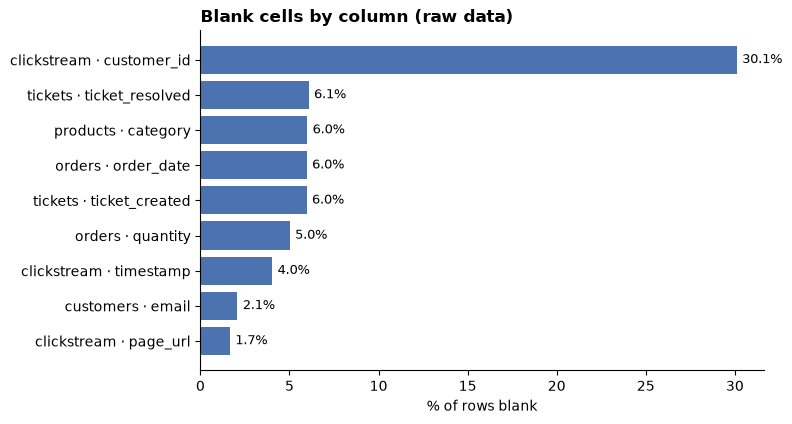

In [17]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BAR = "#4C72B0"

chart = blank_pct[blank_pct["blank_pct"] > 0].sort_values("blank_pct")
labels = chart["table"] + " · " + chart["column"]
fig, ax = plt.subplots(figsize=(8, 0.35 * len(chart) + 1.2))
ax.barh(labels, chart["blank_pct"], color=BAR)
for y, v in enumerate(chart["blank_pct"]):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of rows blank")
ax.set_title("Blank cells by column (raw data)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "m1_blank_cells.png", dpi=150)
plt.show()

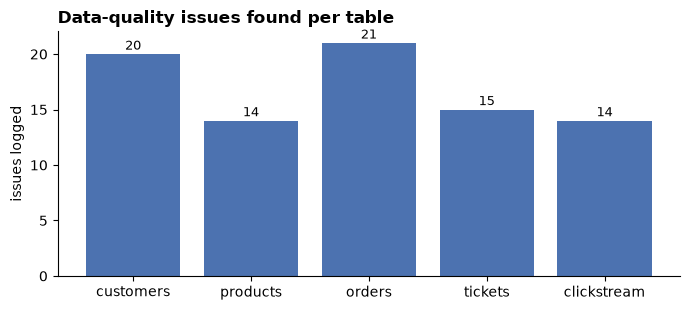

In [18]:
by_table = issue_log.groupby("table")["issue_id"].count().reindex(list(FILES)).fillna(0)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(by_table.index, by_table.values, color=BAR)
for x, v in enumerate(by_table.values):
    ax.text(x, v + 0.4, f"{int(v)}", ha="center", fontsize=9)
ax.set_ylabel("issues logged")
ax.set_title("Data-quality issues found per table", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "m1_issues_by_table.png", dpi=150)
plt.show()

## 14. Save issue log

In [19]:
out_path = OUT_DIR / "issue_log.xlsx"
with pd.ExcelWriter(out_path, engine="xlsxwriter") as writer:
    for sheet, df in [("overview", overview), ("issue_log", issue_log),
                      ("checks_passed", checks_passed), ("column_profile", column_profile)]:
        df.to_excel(writer, sheet_name=sheet, index=False)
        ws = writer.sheets[sheet]
        ws.freeze_panes(1, 0)
        ws.autofilter(0, 0, len(df), len(df.columns) - 1)
        for i, col in enumerate(df.columns):
            width = min(max(df[col].astype(str).str.len().max(), len(col)) + 2, 70)
            ws.set_column(i, i, width)

print("saved:", out_path.resolve())

saved: C:\Users\msibr\OneDrive\Upwork\customer360-data-cleaning\02_process\01_profiling-pandas\output\issue_log.xlsx


## 15. Summary

The issue log is the input for every cleaning milestone:

| Milestone | Table | Issues to fix |
|---|---|---|
| M2 | customers | see `issue_log` filtered on M2 |
| M3 | products | see `issue_log` filtered on M3 |
| M4 | orders | see `issue_log` filtered on M4 |
| M5 | clickstream | see `issue_log` filtered on M5 |
| M6 | tickets | see `issue_log` filtered on M6 |

Every fix made later refers back to an `issue_id` from this log.

In [20]:
issue_log.groupby("milestone").agg(issues=("issue_id", "count"), tables=("table", "unique"))

,issues,tables
milestone,,
M2,20,[customers]
M3,14,[products]
M4,21,[orders]
M5,14,[clickstream]
M6,15,[tickets]
